# Tugas Latihan: Hands-On 1, 4, dan 6

kelompok 1
1. Viola Virjinia (2411511016)
2. Dzaky Ramadhan Amir (2411511002)
3. Habbiel Zidanu Arsa (2411512018)
4. Leonard Dani Agustian (2411513028)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Hands-On 1: Skenario Baru, Gateway Edge-AI untuk Pemrosesan Citra




In [2]:
platforms = ['Raspberry Pi 4', 'Jetson Nano', 'Coral Dev Board', 'Mini PC x86']
kriteria = ['Performa AI', 'Konsumsi Daya', 'Harga', 'Ekosistem/SDK', 'I/O']

skor = pd.DataFrame([
    [2, 4, 5, 5, 5],   # Raspberry Pi 4
    [4, 3, 3, 4, 3],   # Jetson Nano
    [4, 4, 3, 3, 3],   # Coral Dev Board
    [5, 2, 2, 5, 4],   # Mini PC x86
], index=platforms, columns=kriteria)

bobot_A = pd.Series([0.25, 0.20, 0.20, 0.20, 0.15], index=kriteria)  # skenario umum
bobot_B = pd.Series([0.45, 0.15, 0.10, 0.20, 0.10], index=kriteria)  # skenario baru: pemrosesan citra

for nama, b in [('A', bobot_A), ('B', bobot_B)]:
    assert abs(b.sum() - 1) < 1e-9, f'Total bobot skenario {nama} harus 1'

def hitung_skor(skor, bobot):
    return skor.dot(bobot).sort_values(ascending=False)

hasil1 = pd.DataFrame({
    'Skenario A (umum)': hitung_skor(skor, bobot_A),
    'Skenario B (citra)': hitung_skor(skor, bobot_B),
}).round(2)
hasil1


,Skenario A (umum),Skenario B (citra)
Coral Dev Board,3.45,3.60
Jetson Nano,3.45,3.65
Mini PC x86,3.65,4.15
Raspberry Pi 4,4.05,3.50


In [3]:
print('Rekomendasi Skenario A:', hitung_skor(skor, bobot_A).idxmax())
print('Rekomendasi Skenario B:', hitung_skor(skor, bobot_B).idxmax())


Rekomendasi Skenario A: Raspberry Pi 4
Rekomendasi Skenario B: Mini PC x86


**Analisis Hands-On 1**

Rekomendasi **berubah**. Pada skenario A, Raspberry Pi 4 menjadi pilihan terbaik (skor 4.05) karena unggul di harga, ekosistem, dan konsumsi daya. Ketika bobot performa AI dinaikkan menjadi 0.45 pada skenario B, Mini PC x86 menjadi yang terbaik (skor 4.15) dan Raspberry Pi 4 turun ke posisi terakhir. Hal ini menunjukkan bahwa hasil pemilihan platform sangat sensitif terhadap bobot. Untuk pemrosesan citra yang berat, bobot performa harus dipilih berdasarkan kebutuhan inferensi nyata. Jika daya baterai atau biaya menjadi batasan utama, Jetson Nano atau Coral Dev Board bisa menjadi kompromi yang lebih seimbang.


## Hands-On 4: Simulasi ADC 12-bit vs 16-bit untuk Sensor Suhu





In [4]:
Vref = 3.3               # tegangan referensi ADC (V)
offset = 0.5             # tegangan sensor pada 0 °C (V)
sensitivitas = 0.01      # 10 mV/°C
rng = np.random.default_rng(42)
T_true = rng.uniform(-20, 80, 10000)   # suhu sebenarnya (°C)

def kuantisasi(v, bits):
    lsb = Vref / 2**bits
    kode = np.clip(np.round(v / lsb), 0, 2**bits - 1)
    return kode * lsb

def ukur(bits, sigma_v, n_avg=1):
    # tegangan sensor + noise, lalu dikuantisasi ADC, lalu dirata-ratakan
    v = offset + sensitivitas * T_true[:, None] + rng.normal(0, sigma_v, (len(T_true), n_avg))
    v_rata = kuantisasi(v, bits).mean(axis=1)
    T_est = (v_rata - offset) / sensitivitas
    return T_est - T_true   # error (°C)

rows = []
for nama_kondisi, sigma in [('Noise rendah (0.02 mV)', 0.02e-3), ('Noise sensor (0.5 mV)', 0.5e-3)]:
    for bits, n in [(12, 1), (16, 1), (12, 16)]:
        err = ukur(bits, sigma, n)
        rows.append({
            'Kondisi': nama_kondisi,
            'Konfigurasi ADC': f'{bits}-bit, {n}x sampel',
            'RMS error (°C)': round(float(np.sqrt(np.mean(err**2))), 4),
            'Resolusi (°C/LSB)': round((Vref / 2**bits) / sensitivitas, 5),
        })

hasil4 = pd.DataFrame(rows)
hasil4


,Kondisi,Konfigurasi ADC,RMS error (°C),Resolusi (°C/LSB)
0,Noise rendah (0.02 mV),"12-bit, 1x sampel",0.0233,0.08057
1,Noise rendah (0.02 mV),"16-bit, 1x sampel",0.0025,0.00504
2,Noise rendah (0.02 mV),"12-bit, 16x sampel",0.0214,0.08057
3,Noise sensor (0.5 mV),"12-bit, 1x sampel",0.0543,0.08057
4,Noise sensor (0.5 mV),"16-bit, 1x sampel",0.0497,0.00504
5,Noise sensor (0.5 mV),"12-bit, 16x sampel",0.0136,0.08057


**Analisis Hands-On 4**

Resolusi ADC 16-bit memang jauh lebih halus, yaitu sekitar 0,005 °C per LSB dibandingkan 0,081 °C untuk 12-bit. Namun, peningkatan presisi yang sebenarnya dalam hasil bergantung pada noise total sistem:

- **Jika noise sensor kecil (0,02 mV)**, error 12-bit sekitar 0,023 °C dan 16-bit turun menjadi sekitar 0,0025 °C. Secara relatif ini peningkatan sekitar 10x. Namun, 12-bit tanpa oversampling tidak memperbaiki hal ini, karena noise lebih kecil daripada 1 LSB sehingga tidak ada efek dithering.
- **Jika noise sensor realistis (0,5 mV)**, error 16-bit hanya turun dari sekitar 0,054 °C menjadi 0,050 °C. Noise sensor mendominasi, sehingga resolusi ADC tambahan hampir tidak berguna.
- **12-bit dengan oversampling 16x** justru memberi hasil terbaik untuk noise realistis (sekitar 0,014 °C), jauh melampaui 16-bit tanpa oversampling. Noise yang cukup besar membantu dithering sehingga rata-rata sampel menjadi lebih presisi.




## Hands-On 6: Estimasi Umur Baterai dengan Interval Kirim 1 Menit




In [5]:
def estimasi_baterai(interval_menit, kapasitas_mah=2000, dod=0.8,
                     arus_aktif_ma=120, durasi_aktif_s=1.5, arus_sleep_ma=0.01):
    periode_s = interval_menit * 60
    durasi_sleep_s = periode_s - durasi_aktif_s
    muatan_per_siklus = arus_aktif_ma * durasi_aktif_s / 3600 + arus_sleep_ma * durasi_sleep_s / 3600  # mAh
    siklus_per_hari = 86400 / periode_s
    muatan_per_hari = muatan_per_siklus * siklus_per_hari
    umur_hari = kapasitas_mah * dod / muatan_per_hari
    return umur_hari, muatan_per_hari

umur5, q5 = estimasi_baterai(5)
umur1, q1 = estimasi_baterai(1)
print(f'Interval 5 menit: {q5:.2f} mAh/hari -> umur {umur5:.1f} hari (~{umur5/30.44:.1f} bulan)')
print(f'Interval 1 menit: {q1:.2f} mAh/hari -> umur {umur1:.1f} hari (~{umur1/30.44:.1f} bulan)')
print(f'Penurunan umur baterai: {(1 - umur1/umur5)*100:.1f}%')


Interval 5 menit: 14.64 mAh/hari -> umur 109.3 hari (~3.6 bulan)
Interval 1 menit: 72.23 mAh/hari -> umur 22.2 hari (~0.7 bulan)
Penurunan umur baterai: 79.7%


**Hasil perhitungan ulang:** Dengan interval 5 menit, konsumsi sekitar 14,6 mAh/hari dan umur baterai sekitar **109 hari** (±3,6 bulan). Dengan interval 1 menit, konsumsi naik menjadi sekitar 72,2 mAh/hari dan umur baterai turun menjadi sekitar **22 hari**. Umur baterai turun sekitar 80%, padahal interval hanya berkurang 5x. Ini terjadi karena konsumsi didominasi oleh energi transmisi aktif, bukan oleh arus sleep.


## Trade-off: Responsivitas Monitoring vs Umur Baterai




In [6]:
intervals = [1, 2, 5, 10, 15, 30]
rows = []
for m in intervals:
    umur, q = estimasi_baterai(m)
    rows.append({
        'Interval kirim (menit)': m,
        'Konsumsi (mAh/hari)': round(q, 2),
        'Umur baterai (hari)': round(umur, 1),
        'Latensi deteksi maks (menit)': m,
    })
tabel = pd.DataFrame(rows)
tabel


,Interval kirim (menit),Konsumsi (mAh/hari),Umur baterai (hari),Latensi deteksi maks (menit)
0,1,72.23,22.2,1
1,2,36.24,44.2,2
2,5,14.64,109.3,5
3,10,7.44,215.1,10
4,15,5.04,317.5,15
5,30,2.64,606.1,30


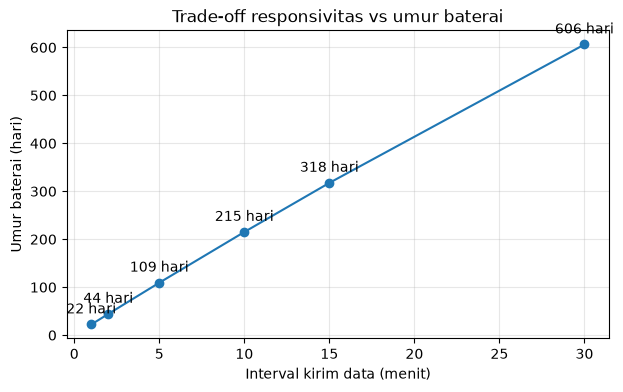

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabel['Interval kirim (menit)'], tabel['Umur baterai (hari)'], marker='o')
for x, y in zip(tabel['Interval kirim (menit)'], tabel['Umur baterai (hari)']):
    ax.annotate(f'{y:.0f} hari', (x, y), textcoords='offset points', xytext=(0, 8), ha='center')
ax.set_xlabel('Interval kirim data (menit)')
ax.set_ylabel('Umur baterai (hari)')
ax.set_title('Trade-off responsivitas vs umur baterai')
ax.grid(True, alpha=0.3)
plt.show()


**Analisis trade-off**

Mengirim data setiap 1 menit membuat sistem jauh lebih responsif. Kejadian seperti lonjakan suhu terdeteksi dalam waktu maksimal 1 menit, bukan 5 menit. Namun, biayanya besar: umur baterai turun dari sekitar 109 hari menjadi 22 hari, dan frekuensi penggantian atau pengisian ulang baterai meningkat drastis.

Hubungan ini tidak linear. Dari 1 ke 5 menit, umur baterai naik sekitar 5x. Dari 5 ke 30 menit, umur baterai naik lagi sekitar 5x, tetapi responsivitas turun 6x. Artinya, pilihan interval sebaiknya ditentukan oleh **kebutuhan aplikasi**. Beberapa strategi yang bisa dipertimbangkan:

- **Interval adaptif:** kirim tiap 1 menit hanya saat nilai suhu berubah signifikan atau mendekati ambang batas, dan tiap 15 hingga 30 menit saat kondisi stabil.
- **Event-driven:** kirim segera saat ambang batas dilampaui, lalu kirim data rutin dengan interval panjang.
- **Kompresi atau batching:** kumpulkan beberapa pembacaan lalu kirim sekaligus untuk memperkecil overhead transmisi.


